# 07 · Optional experiment: does small-scale sea-surface temperature matter for the NAO?

**Question for this notebook.** The project began with the question of whether small-scale ocean
features (eddies and sharp fronts) influence the winter NAO. The coupled models of the earlier
notebooks cannot answer it, because both have an eddy-rich ocean. EERIE also published a set of
controlled experiments that can test one part of it: the atmosphere's **sensitivity to small-scale
sea-surface temperature (SST) variability**.

**The experiments.** These are atmosphere-only runs of the IFS model, 1980–2023. The ocean is not
simulated; the sea-surface temperature is prescribed from satellite observations (ESA-CCI).

| Run | Sea-surface temperature given to the atmosphere | Members |
|---|---|---|
| `hist` | observed, with all its small-scale detail | 10 at 28 km, 1 at 9 km |
| `hist-c-0-a-lr20` | the same, but with the SST *anomalies* spatially filtered ("LR20"), removing small-scale features | 10 at 28 km, 1 at 9 km |
| `hist-c-lr20-a-0` | a third variant; from its name, the filter is applied to the SST *climatology* instead of the anomalies | 10 at 28 km |

Everything else is identical between the runs, so any systematic difference in the NAO comes from
the SST detail.

**What has and has not been verified.** The descriptions above are from the public EERIE
catalogue. The exact definition of the "LR20" filter, and what the third variant changes, are **not**
documented there and have not been verified. Results are therefore described as *sensitivity to
filtered SST forcing*. They are **not** a statement about a coupled effect of ocean eddies: an
atmosphere-only run cannot show how the ocean would respond in turn.

**Why members matter.** The NAO is mostly internal atmospheric noise. Two runs of the *same*
experiment that start from slightly different conditions give different NAO histories. A difference
between two experiments means something only if it is larger than the differences between members
of one experiment. The 28 km runs have ten members each, which makes that comparison possible.
The 9 km pair has one member each and is shown for information only.

**Data.** Monthly sea-level pressure on the North Atlantic box, 1° grid; 43 winters, 1981–2023.
Daily data were not downloaded for these runs, so this notebook is about the NAO only.

**Sections**
1. Setup
2. Findings
3. Is the mean winter pressure different?
4. Is the NAO pattern different?
5. Is the NAO stronger or weaker?
6. Does the atmosphere follow the observed NAO winters?
7. Limitations
8. Open questions

## Background: the terms used in this notebook

| Term | What it means here |
|---|---|
| **Atmosphere-only (AMIP) run** | A simulation of the atmosphere with the sea-surface temperature and sea ice prescribed from observations, instead of a simulated ocean. |
| **Ensemble, member** | Several runs of the same experiment that differ only in tiny details of their starting state. Their spread shows how much is chance. |
| **Ensemble mean** | The average over members. Averaging cancels each member's random weather and leaves what is common to all: the part *caused* by the prescribed SST and other forcings. |
| **NAO along the ERA5 pattern** | Each run's winter pressure maps are measured against the real-world NAO pattern from notebook 04, in units of the ERA5 standard deviation. The same ruler is used for every run. |
| **Welch t-test** | A standard test of whether two groups (here: ten members of one experiment and ten of another) differ by more than their internal spread would explain. |
| **FDR control** | As in notebook 06: a correction so that maps with thousands of tests are not dotted with false alarms. |

**Colours in this notebook.** Green: observed SST (`hist`). Yellow: filtered SST anomalies.
Pink: the third variant. Dark grey: ERA5. In difference maps, grey means no difference.

## 1. Setup

**What this cell does.** Loads the project code and names the experiments.

In [1]:
import sys, warnings
sys.path.insert(0, '../src')
warnings.filterwarnings('ignore')

import numpy as np
import pandas as pd
import xarray as xr
from scipy import stats
from eerie_uk import climatology as clim, nao, plotting, relationships as rel, store

pd.set_option('display.width', 220, 'display.float_format', '{:.2f}'.format)
RUNS = ['hist', 'hist-c-0-a-lr20', 'hist-c-lr20-a-0']       # 28 km, ten members each
LABEL = plotting.SOURCE_LABELS
BASE = (1980, 2023)

**What this cell does.** Loads monthly pressure for the three 28 km experiments (ten members each)
and the 9 km pair, and turns each member into one pressure-anomaly map per winter, using that
experiment's own 1980–2023 climatology. It also rebuilds the ERA5 NAO pattern from notebook 04
(1951–2014), which serves as the common ruler.

In [2]:
psl = {run: store.load(f'ifs-amip-tco399.{run}', 'mon', 'psl', 'north_atlantic') for run in RUNS}
psl_9km = {run: store.load(f'ifs-amip-tco1279.{run}', 'mon', 'psl', 'north_atlantic') for run in RUNS[:2]}
winters = {run: nao.winter_anomalies(da, BASE) for run, da in psl.items()}
winters_9km = {run: nao.winter_anomalies(da, BASE) for run, da in psl_9km.items()}

era5_winters = nao.winter_anomalies(store.load('era5', 'mon', 'psl', 'north_atlantic'))
era5 = nao.leading_eof(era5_winters)

w = winters['hist']
print('28 km:', w.sizes['realization'], 'members,', w.sizes['year'], 'winters', int(w.year[0]), 'to', int(w.year[-1]))
print('9 km :', winters_9km['hist'].sizes['year'], 'winters, 1 member per experiment')

28 km: 10 members, 43 winters 1981 to 2023
9 km : 43 winters, 1 member per experiment


## 2. Findings

43 winters, 1981–2023; ten members per experiment at 28 km. "Strength" is the standard deviation of the winter NAO index along the ERA5 pattern, in ERA5 units.

| | Observed SST (`hist`) | Filtered SST anomalies | Third variant |
|---|---|---|---|
| Mean winter pressure, change from `hist` | – | at most 0.5 hPa, typically 0.13 hPa; significant nowhere | at most 0.4 hPa, typically 0.14 hPa; significant nowhere |
| … expressed as a shift along the NAO | – | +0.03 SD (p = 0.75) | +0.02 SD (p = 0.78) |
| NAO pattern correlation with ERA5 | 0.99 | 0.99 | 0.99 |
| Variance explained by the NAO pattern | 41% | 42% | 42% |
| NAO strength, ensemble mean | 0.87 | 0.86 | 0.91 |
| NAO strength, range across the ten members | 0.70 to 1.00 | 0.78 to 0.94 | 0.84 to 0.97 |
| Difference in strength from `hist` | – | −0.01 (p = 0.73) | +0.04 (p = 0.24) |
| Correlation of the ensemble-mean NAO with ERA5 | 0.27 | 0.09 | 0.25 |

**What this means, in plain words**

1. **Filtering the small-scale SST makes no detectable difference to the winter NAO in these runs.** The mean winter pressure changes by a few tenths of a hectopascal at most, against NAO swings of 4–5 hPa, and the change is not significant anywhere in the North Atlantic box. The NAO pattern is the same (pattern correlation 1.00 between experiments). The NAO strength differs by −1% and +4%, well inside the spread between members of a single experiment.
2. **This is a null result with a stated resolution.** Ten members can detect a change in NAO strength of roughly 10%. A smaller effect, or an effect on something other than the seasonal-mean NAO (storm tracks, local rainfall near ocean fronts, daily extremes), cannot be ruled out with this data.
3. **Chance alone moves NAO strength a lot.** Ten runs of the *same* model with the *same* SST give NAO strengths from 0.70 to 1.00 over 43 winters. This matters for the earlier notebooks: the coupled IFS-FESOM2-SR value of 0.71 (one member) sits at the lower edge of that range, so its "weak NAO" may be partly chance. ICON-ESM-ER's 0.59 lies below the whole range.
4. **The atmosphere-only model has a realistic NAO pattern** (pattern correlation 0.99 with ERA5, far better than either single-member coupled run in notebook 04, helped by pooling 430 winters) and a strength of about 0.87 of ERA5's, with ERA5's own 1981–2014 value (1.02) just above the highest member.
5. **Only a small part of the winter NAO follows the observed sequence of winters.** The ensemble-mean NAO correlates with ERA5 at 0.27 for observed SST, below the 0.34 needed for significance with 34 winters. The value for filtered anomalies is lower (0.09), but with these sample sizes that difference cannot be distinguished from chance and no conclusion is drawn from it.

**Answer to the question.** In this atmosphere-only model at 28 km, the seasonal-mean winter NAO is not measurably sensitive to small-scale SST variability. This says nothing about a coupled ocean–atmosphere effect, and the exact meaning of the filter remains unverified.

## 3. Is the mean winter pressure different?

The first question is the simplest: does the average winter circulation change when the SST detail
is filtered?

**What this cell does.** Computes each member's 1981–2023 winter-mean pressure, then the
difference between experiments (ensemble mean of each filtered experiment minus the ensemble mean
of `hist`). A Welch t-test at every grid point compares that difference with the spread across the
ten members of each experiment; dots mark points that pass the test with FDR control.

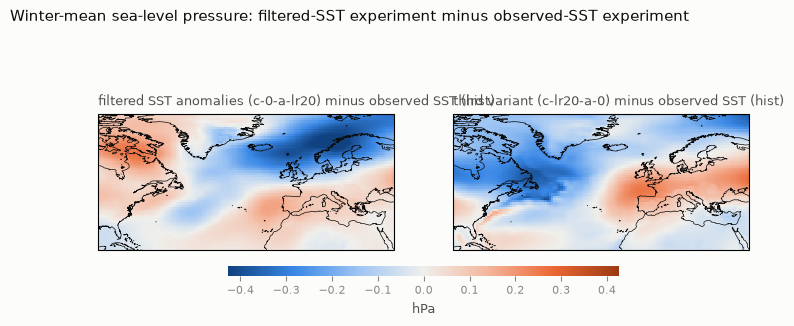

In [3]:
mean_winter = {run: clim.climatology(da, 'DJF') for run, da in psl.items()}       # (realization, lat, lon)
tests = {run: rel.ensemble_difference(mean_winter[run], mean_winter['hist']) for run in RUNS[1:]}
plotting.plot_field_panels({f'{LABEL[run]} minus {LABEL["hist"]}': tests[run].difference for run in RUNS[1:]},
                           units='hPa', diverging=True, columns=2,
                           stipple={f'{LABEL[run]} minus {LABEL["hist"]}': rel.fdr_mask(tests[run].p) for run in RUNS[1:]},
                           title='Winter-mean sea-level pressure: filtered-SST experiment minus observed-SST experiment');

**Figure 1.** Change in average winter pressure caused by filtering the SST. Orange: higher
pressure with filtered SST; blue: lower. Dots: the change is larger than the member spread can
explain. For scale, one standard deviation of the real NAO is 4–5 hPa at its centres.

**What this cell does.** Puts numbers on Figure 1: the largest and the typical size of the
mean-pressure change, the share of the box where it is significant, and how the change projects
onto the NAO pattern (in NAO standard deviations: +1 would mean the filtered run sits permanently
in a +1 SD NAO state compared with `hist`).

In [4]:
rows = []
for run in RUNS[1:]:
    difference = tests[run].difference
    members = [nao.project_map(mean_winter[run].sel(realization=r) - mean_winter['hist'].mean('realization'), era5.vector) / era5.amplitude
               for r in mean_winter[run].realization.values]
    control = [nao.project_map(mean_winter['hist'].sel(realization=r) - mean_winter['hist'].mean('realization'), era5.vector) / era5.amplitude
               for r in mean_winter['hist'].realization.values]
    rows.append({'experiment': LABEL[run], 'largest change (hPa)': float(abs(difference).max()),
                 'typical change (hPa, RMS)': float(np.sqrt((difference ** 2).weighted(np.cos(np.deg2rad(difference.lat))).mean())),
                 'area significant %': 100 * float(rel.fdr_mask(tests[run].p).mean()),
                 'mean shift along the NAO (SD)': float(np.mean(members)),
                 'member spread of that shift (SD)': float(np.std(control, ddof=1)),
                 'p value of the shift': float(stats.ttest_ind(members, control, equal_var=False).pvalue)})
pd.DataFrame(rows)

,experiment,largest change (hPa),"typical change (hPa, RMS)",area significant %,mean shift along the NAO (SD),member spread of that shift (SD),p value of the shift
0,filtered SST anomalies (c-0-a-lr20),0.47,0.13,0.00,0.03,0.19,0.75
1,third variant (c-lr20-a-0),0.40,0.14,0.00,0.02,0.19,0.78


## 4. Is the NAO pattern different?

**What this cell does.** Computes the leading pressure pattern of each experiment, pooling all ten
members (430 winter maps per experiment), and maps them next to the ERA5 pattern.

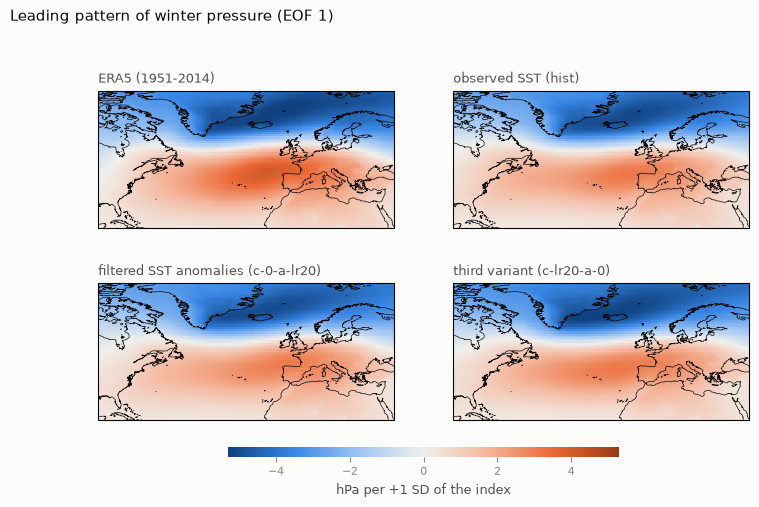

In [5]:
def pooled(run):
    stacked = winters[run].stack(sample=('realization', 'year')).transpose('sample', 'lat', 'lon')
    return stacked.reset_index('sample', drop=True).rename(sample='year').assign_coords(year=np.arange(stacked.sizes['sample']))
eofs = {run: nao.leading_eof(pooled(run)) for run in RUNS}
plotting.plot_field_panels({'ERA5 (1951-2014)': era5.pattern, **{LABEL[run]: eofs[run].pattern for run in RUNS}},
                           units='hPa per +1 SD of the index', diverging=True, columns=2,
                           title='Leading pattern of winter pressure (EOF 1)');

**Figure 2.** The NAO pattern in ERA5 and in each experiment (ten members pooled). With 430 winter
maps the experiment patterns are much less noisy than the single-member coupled-model patterns of
notebook 04.

**What this cell does.** Summarises the patterns: variance explained, the two centres, and pattern
correlation with ERA5 and with the `hist` experiment.

In [6]:
rows = []
for run in RUNS:
    e = eofs[run]
    rows.append({'experiment': LABEL[run], 'EOF1 variance %': 100 * e.explained[0], 'EOF2 variance %': 100 * e.explained[1],
                 **nao.centres(e.pattern),
                 'pattern correlation with ERA5': clim.pattern_stats(e.pattern, era5.pattern)['pattern correlation'],
                 'pattern correlation with hist': clim.pattern_stats(e.pattern, eofs['hist'].pattern)['pattern correlation']})
pd.DataFrame(rows)

,experiment,EOF1 variance %,EOF2 variance %,north lat,north lon,north hPa,south lat,south lon,south hPa,pattern correlation with ERA5,pattern correlation with hist
0,observed SST (hist),40.68,18.85,68.38,-12.62,-5.12,43.38,-13.62,3.16,0.99,1.00
1,filtered SST anomalies (c-0-a-lr20),42.00,17.50,65.38,-30.62,-5.04,45.38,-5.62,3.06,0.99,1.00
2,third variant (c-lr20-a-0),42.47,19.11,65.38,-31.62,-5.40,42.38,-18.62,3.14,0.99,1.00


## 5. Is the NAO stronger or weaker?

The coupled models of notebook 04 had a weaker NAO than ERA5. Does SST detail change the strength
of the NAO in these atmosphere-only runs?

**What this cell does.** Measures the NAO strength of every member: the standard deviation of its
winter index along the ERA5 pattern, in ERA5 units (1.00 = as strong as ERA5 over 1951–2014).
ERA5's own value for the same 34 overlapping winters (1981–2014) is printed for reference.

ERA5, winters 1981-2014: 1.02
9 km single members   : {'observed SST (hist)': 0.79, 'filtered SST anomalies (c-0-a-lr20)': 0.84}


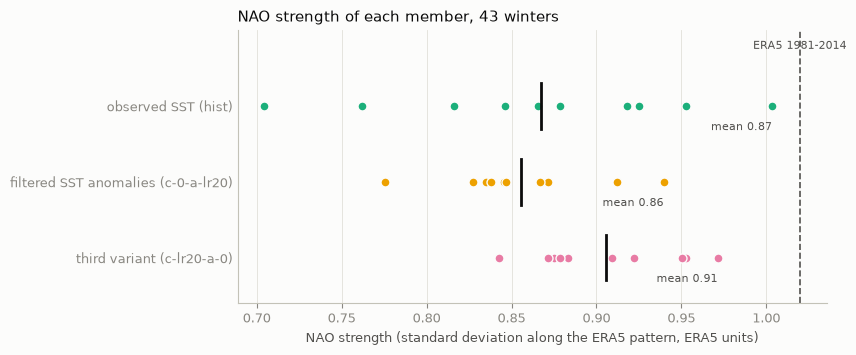

In [7]:
index = {run: nao.project(winters[run], era5.vector) / era5.amplitude for run in RUNS}          # (year, realization)
index_9km = {run: nao.project(winters_9km[run], era5.vector) / era5.amplitude for run in RUNS[:2]}
strength = {run: index[run].std('year', ddof=1).values for run in RUNS}
era5_overlap = (nao.project(era5_winters, era5.vector) / era5.amplitude).sel(year=slice(1981, 2014))
print('ERA5, winters 1981-2014:', round(float(era5_overlap.std(ddof=1)), 2))
print('9 km single members   :', {LABEL[run]: round(float(index_9km[run].std(ddof=1)), 2) for run in RUNS[:2]})
plotting.plot_member_dots(strength, xlabel='NAO strength (standard deviation along the ERA5 pattern, ERA5 units)',
                          title='NAO strength of each member, 43 winters', reference=float(era5_overlap.std(ddof=1)),
                          reference_label='ERA5 1981-2014');

**Figure 3.** Each dot is one member; the black bar is the ensemble mean. The spread of the dots
within one row is pure chance: identical model, identical SST. Two experiments differ in NAO
strength only if their rows are clearly offset from each other.

**What this cell does.** Tests whether the experiments differ in NAO strength by more than their
member spread (Welch t-test on the ten member values of each).

In [8]:
rows = []
for run in RUNS:
    row = {'experiment': LABEL[run], 'mean strength': strength[run].mean(), 'lowest member': strength[run].min(),
           'highest member': strength[run].max(), 'member spread (SD)': strength[run].std(ddof=1)}
    if run != 'hist':
        row['difference from hist'] = strength[run].mean() - strength['hist'].mean()
        row['p value'] = float(stats.ttest_ind(strength[run], strength['hist'], equal_var=False).pvalue)
    rows.append(row)
pd.DataFrame(rows)

,experiment,mean strength,lowest member,highest member,member spread (SD),difference from hist,p value
0,observed SST (hist),0.87,0.70,1.00,0.09,NaN,NaN
1,filtered SST anomalies (c-0-a-lr20),0.86,0.78,0.94,0.05,-0.01,0.73
2,third variant (c-lr20-a-0),0.91,0.84,0.97,0.04,0.04,0.24


## 6. Does the atmosphere follow the observed NAO winters?

Because these runs are given the *observed* SST, part of their NAO may follow the real sequence of
winters. If it does, that part is caused by the SST (and other prescribed forcings), and one can
ask whether filtering the SST weakens it.

**What this cell does.** Averages the NAO index over the ten members of each experiment, which
removes most of the random part, and plots it with the ERA5 index for the overlapping winters.

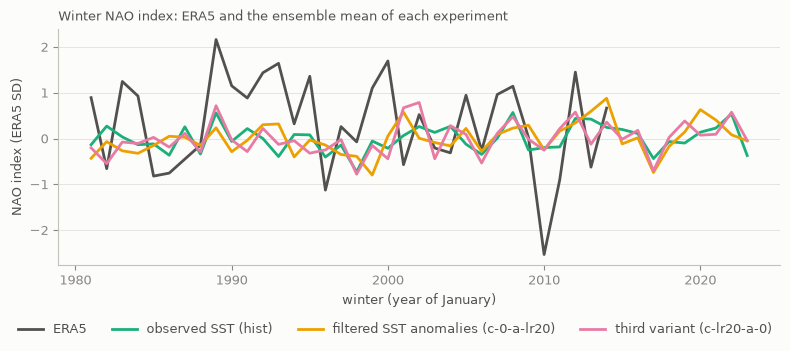

In [9]:
ensemble_mean = {run: index[run].mean('realization') for run in RUNS}
panel = {'era5': (era5_overlap.year.values, era5_overlap.values)}
panel.update({run: (ensemble_mean[run].year.values, ensemble_mean[run].values) for run in RUNS})
plotting.plot_line_panels({'Winter NAO index: ERA5 and the ensemble mean of each experiment': panel},
                          ylabel='NAO index (ERA5 SD)', xlabel='winter (year of January)', columns=1);

**Figure 4.** ERA5 (grey) is one real history and swings by several SD. The coloured lines are
averages over ten members, so their swings are much smaller: what remains is the part of the NAO
that the prescribed SST and forcings determine.

**What this cell does.** Quantifies Figure 4 for the overlapping winters 1981–2014: the correlation
of each experiment's ensemble-mean NAO with the ERA5 NAO, the range of that correlation across
individual members, and the share of each experiment's NAO variance that is common to all members
(the "forced" share).

In [10]:
rows = []
for run in RUNS:
    members = index[run].sel(year=slice(1981, 2014))
    correlations = [float(np.corrcoef(members.sel(realization=r), era5_overlap)[0, 1]) for r in members.realization.values]
    total = float(index[run].var('year', ddof=1).mean())
    forced = float(ensemble_mean[run].var(ddof=1)) - total / index[run].sizes['realization']
    rows.append({'experiment': LABEL[run],
                 'correlation of ensemble mean with ERA5': float(np.corrcoef(ensemble_mean[run].sel(year=slice(1981, 2014)), era5_overlap)[0, 1]),
                 'lowest member': min(correlations), 'highest member': max(correlations), 'mean of members': float(np.mean(correlations)),
                 'forced share of NAO variance %': 100 * max(forced, 0.0) / total})
print('with 34 winters, a correlation above about 0.34 is significant at the 5% level')
pd.DataFrame(rows)

with 34 winters, a correlation above about 0.34 is significant at the 5% level


,experiment,correlation of ensemble mean with ERA5,lowest member,highest member,mean of members,forced share of NAO variance %
0,observed SST (hist),0.27,-0.05,0.34,0.09,1.54
1,filtered SST anomalies (c-0-a-lr20),0.09,-0.33,0.33,0.03,6.18
2,third variant (c-lr20-a-0),0.25,-0.15,0.34,0.11,6.32


## 7. Limitations

- **What the filter does is not verified.** "LR20" and the third variant are interpreted from their
  names and one-line catalogue descriptions.
- **Atmosphere-only.** The ocean cannot respond. This tests sensitivity to prescribed SST detail,
  not the effect of ocean eddies in a coupled system.
- **One atmosphere model at 28 km.** A 28 km atmosphere may not respond to small SST features the
  way a finer one would; the 9 km pair has only one member each, too few to say.
- **NAO and mean pressure only.** No storm tracks, no extremes, no daily data.
- **Monthly means on a 1° grid.** Small-scale local responses near SST fronts are not visible here.
- **The NAO ruler is the ERA5 pattern of 1951–2014,** while the runs cover 1981–2023.
- **Ten members** detect differences in NAO strength of roughly 10% or more; smaller effects would
  be missed.

## 8. Open questions

1. What exactly does the LR20 filter remove, and at what spatial scale?
2. Would the atmosphere respond more to filtered SST at 9 km than at 28 km? The 9 km pair has only
   one member each, too few to say.
3. Does filtering SST affect daily extremes or the storm track even where the seasonal-mean NAO is
   unchanged?